In [2]:
import matplotlib.pyplot as plt

In [2]:
import matplotlib.pyplot as plt

In [3]:
import pandas as pd

df = pd.read_excel("bitcoin market features table 10.xlxs.xlsx")

In [4]:
df[["trade_date", "close_price"]].head(10)

,trade_date,close_price
0,2015-10-13,249.507996
1,2016-05-31,531.385986
2,2020-06-22,9648.717773
3,2019-12-08,7564.345215
4,2020-02-11,10208.236330
5,2019-04-21,5314.531250
6,2022-08-14,24319.333980
7,2023-02-08,22939.398440
8,2024-06-02,67751.601560
9,2025-02-09,96500.093750


In [6]:
df["trade_date"] = pd.to_datetime(df["trade_date"])

In [8]:
df = df.sort_values("trade_date")

In [10]:
df["market_cycle"] = df["trend_direction"]

In [12]:
df["market_cycle"].value_counts()

market_cycle
Bullish    2565
Bearish    1569
Neutral      50
Name: count, dtype: int64

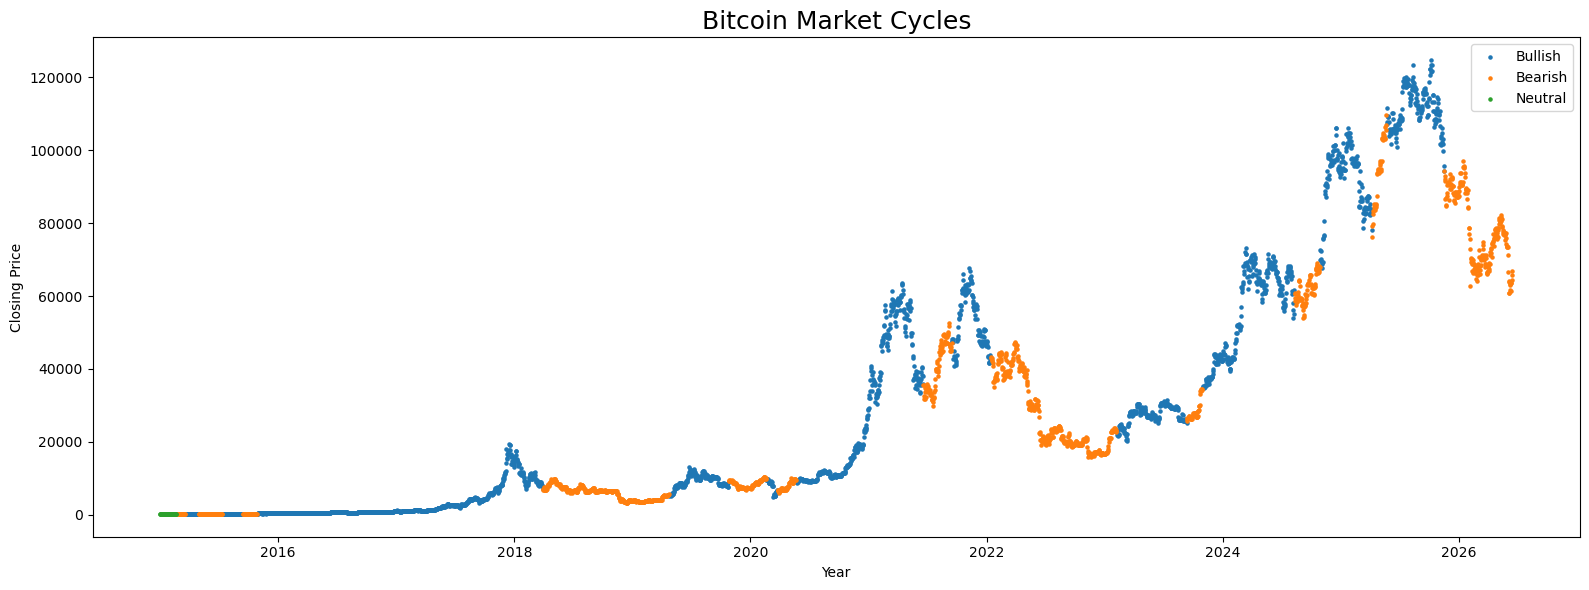

In [14]:
plt.figure(figsize=(16,6))

bull = df[df["market_cycle"]=="Bullish"]
bear = df[df["market_cycle"]=="Bearish"]
neutral = df[df["market_cycle"]=="Neutral"]

plt.scatter(
    bull["trade_date"],
    bull["close_price"],
    label="Bullish",
    s=5
)

plt.scatter(
    bear["trade_date"],
    bear["close_price"],
    label="Bearish",
    s=5
)

plt.scatter(
    neutral["trade_date"],
    neutral["close_price"],
    label="Neutral",
    s=5
)

plt.title("Bitcoin Market Cycles", fontsize=18)

plt.xlabel("Year")

plt.ylabel("Closing Price")

plt.legend()

plt.tight_layout()

plt.show()

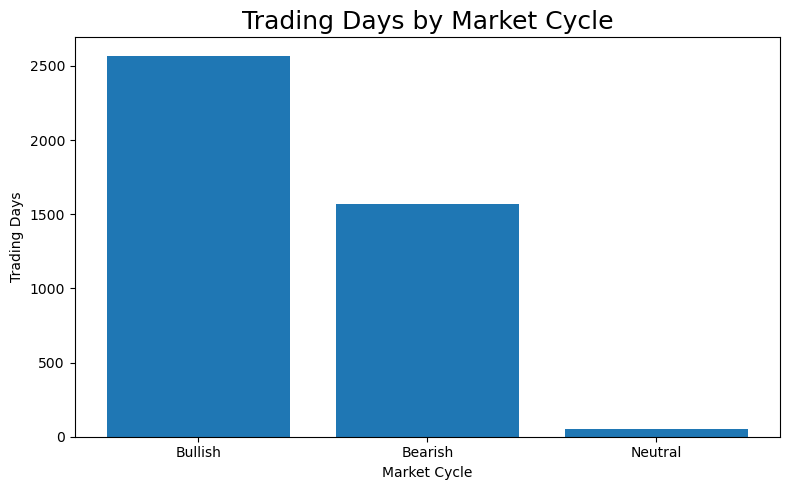

In [16]:
cycle_days = df["market_cycle"].value_counts()

plt.figure(figsize=(8,5))

plt.bar(cycle_days.index, cycle_days.values)

plt.title("Trading Days by Market Cycle", fontsize=18)

plt.xlabel("Market Cycle")

plt.ylabel("Trading Days")

plt.tight_layout()

plt.show()

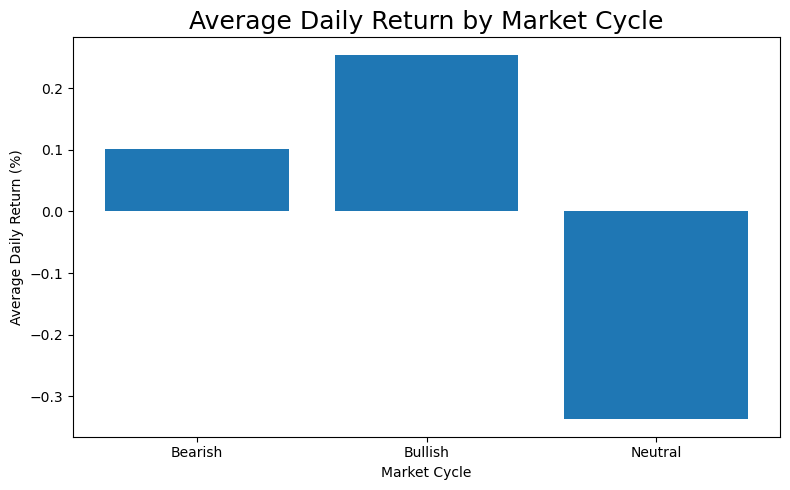

In [18]:
cycle_return = (
    df.groupby("market_cycle")["daily_return_pct"]
      .mean()
)

plt.figure(figsize=(8,5))

plt.bar(
    cycle_return.index,
    cycle_return.values
)

plt.title("Average Daily Return by Market Cycle", fontsize=18)

plt.xlabel("Market Cycle")

plt.ylabel("Average Daily Return (%)")

plt.tight_layout()

plt.show()

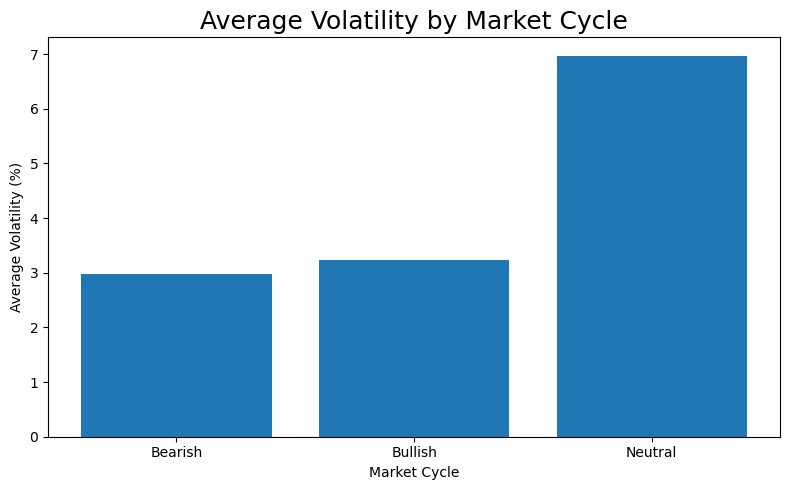

In [19]:
cycle_volatility = (
    df.groupby("market_cycle")["volatility_30d"]
      .mean()
)

plt.figure(figsize=(8,5))

plt.bar(
    cycle_volatility.index,
    cycle_volatility.values
)

plt.title("Average Volatility by Market Cycle", fontsize=18)

plt.xlabel("Market Cycle")

plt.ylabel("Average Volatility (%)")

plt.tight_layout()

plt.show()